In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage

In [5]:
df = pd.read_csv("sales_data_sample.csv", encoding = "unicode_escape")
print(df.shape)
df.head()

(2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [6]:
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

In [7]:
X = X.dropna()

In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

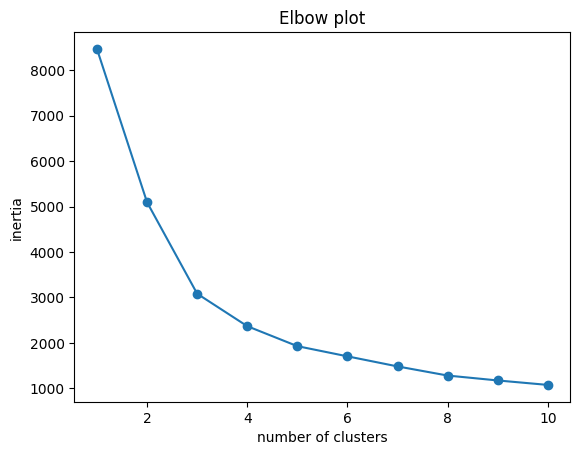

In [11]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia, marker = "o")
plt.title("Elbow plot")
plt.xlabel("number of clusters")
plt.ylabel("inertia")
plt.show()

In [14]:
kmeans = KMeans(n_clusters = 3, random_state= 42)
kmeans_label = kmeans.fit_predict(X_scaled)

print(pd.Series(kmeans_label).value_counts().sort_index())

0     881
1     907
2    1035
Name: count, dtype: int64


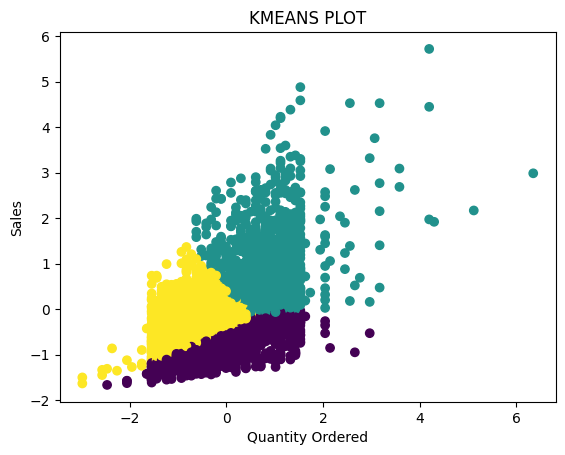

In [15]:
plt.scatter(
    X_scaled[:, 0], X_scaled[:, 2],
    c = kmeans_label, cmap = "viridis"
)
plt.title("KMEANS PLOT")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

In [22]:
hierarchy = AgglomerativeClustering(n_clusters  = 3)
H_labels = hierarchy.fit_predict(X_scaled)

print(pd.Series(H_labels).value_counts().sort_index())

0    1014
1     685
2    1124
Name: count, dtype: int64


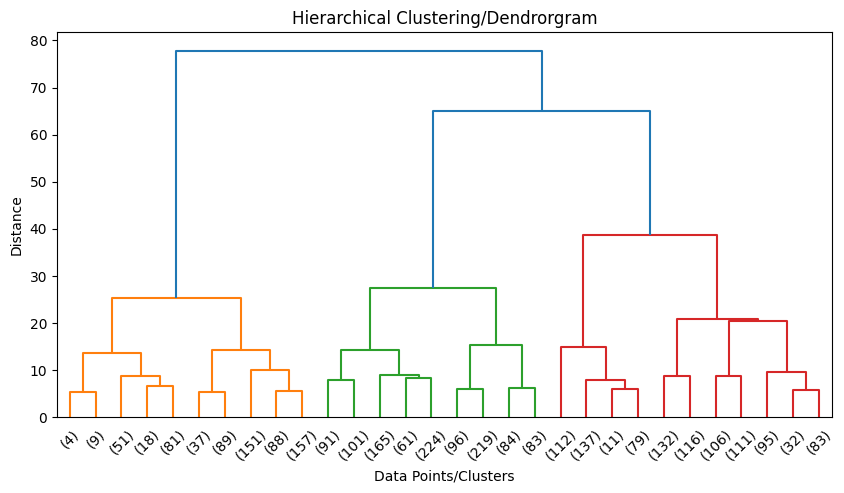

In [25]:
linked = linkage(X_scaled, method = "ward")

plt.figure(figsize=(10, 5))
dendrogram(linked, truncate_mode = "lastp", p = 30)
plt.title("Hierarchical Clustering/Dendrorgram")
plt.xlabel("Data Points/Clusters")
plt.ylabel("Distance")
plt.show()